# 9. Hybrid Multi-Dimensional Stack: Direct Mode Matching Between 1D Grating and 2D Array

## Physical Motivation & Learning Objectives
EMUstack natively matches transverse electromagnetic fields across layers of **different geometric dimensionality** without requiring artificial intermediate air gaps. In this tutorial:
1. We construct a hybrid stack combining a 1D lamellar grating directly on top of a 2D nanowire array.
2. We verify energy conservation across the 1D-to-2D S-matrix interface.

> [!NOTE]
> **Meshing Workflow: Classic Gmsh / Pre-Generated Mesh (`examples/`)**
> The 2D nanostructure layer is meshed using Gmsh via `make_mesh_now=True`.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import concurrent.futures

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack


## Hybrid Stack Geometry Setup


In [2]:
wavelengths = np.linspace(600, 900, 4)
period = 600.0        # nm
NW_diameter = 120.0   # nm

light_list = [objects.Light(wl, max_order_PWs=2, theta=0.0, phi=0.0) for wl in wavelengths]

superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, loss=False)
substrate   = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Si_c, loss=True)

grating = objects.NanoStruct(
    '1D_array', period, int(round(0.7 * period)), height_nm=200.0,
    background=materials.Material(1.45),
    inclusion_a=materials.Material(3.5),
    loss=True, lc_bkg=0.01, plt_msh=False, world_1d=False
)

NW_array = objects.NanoStruct(
    '2D_array', period, NW_diameter,
    height_nm=2330.0,
    inclusion_a=materials.Si_c,
    background=materials.Air,
    loss=True,
    make_mesh_now=True, lc_bkg=0.1, lc2=2.0,
    plt_msh=False
)

def simulate_stack(light):
    sim_sup = superstrate.calc_modes(light)
    sim_grt = grating.calc_modes(light, num_BMs=20)
    sim_nw  = NW_array.calc_modes(light, num_BMs=30)
    sim_sub = substrate.calc_modes(light)
    
    # Bottom to top: Substrate -> 2D NWs -> 1D Grating -> Superstrate
    stk = Stack((sim_sub, sim_nw, sim_grt, sim_sup))
    stk.calc_scat(pol='TE')
    return stk

with concurrent.futures.ThreadPoolExecutor() as executor:
    stacks_list = list(executor.map(simulate_stack, light_list))


 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.
 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.
 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.
 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.


## Hybrid Stack Spectra


<ipython-input-1-5c183317db48>:2: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


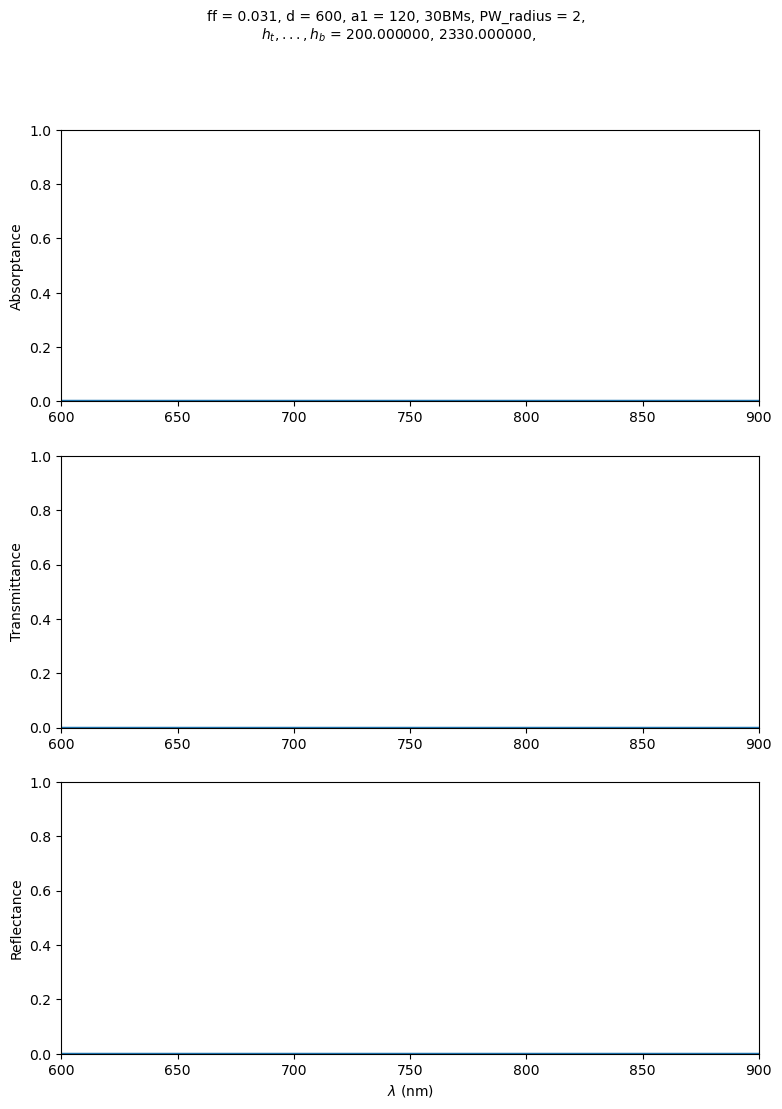

In [3]:
fig_tra = plotting.t_r_a_plots(stacks_list, save_pdf=False, save_txt=False)
plt.show()


## Physical Interpretation
Direct mode-matching evaluates the spatial overlap integrals between 1D and 2D Bloch modes analytically, avoiding the unphysical reflections associated with artificial dielectric buffer layers.
